<a href="https://colab.research.google.com/github/MarcoIppolito96/tuia-dog-recognition-app/blob/feature%2Ftp2-razas-perros/2-train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab (si corresponde):** https://colab.research.google.com/drive/1NuKED8eCmr7uIZXakTYhexu_tuPo_pbk#scrollTo=cecf034b

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno: Ippolito Marco

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [1]:
REPO_URL = "https://github.com/MarcoIppolito96/tuia-dog-recognition-app.git"

# En Kaggle la carpeta de trabajo es /kaggle/working
%cd /kaggle/working
!git clone -b feature/tp2-razas-perros $REPO_URL proyecto
%cd /kaggle/working/proyecto

/kaggle/working
Cloning into 'proyecto'...
remote: Enumerating objects: 213, done.
remote: Counting objects: 100% (77/77), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 213 (delta 59), reused 43 (delta 43), pack-reused 136 (from 1)
Receiving objects: 100% (213/213), 23.76 MiB | 35.36 MiB/s, done.
Resolving deltas: 100% (115/115), done.
/kaggle/working/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [2]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [3]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.

In [4]:
!python scripts/download_dataset.py

import glob, shutil
import pandas as pd

# Splits definidos en 1-pre-processing.ipynb (ruta relativa a DATASET_PATH)
splits = pd.read_csv(settings.data_path / "splits" / "splits.csv")
splits["ruta"] = [str(settings.dataset_path / r) for r in splits["ruta"]]
print(splits["split"].value_counts().reindex(["train", "valid", "test"]))

# Conjunto independiente: subido como dataset de Kaggle (copia del armado en la notebook 1)
origen = Path(glob.glob("/kaggle/input/**/independiente.csv", recursive=True)[0]).parent
shutil.copytree(origen, settings.dataset_path / "independent", dirs_exist_ok=True)
indep = pd.read_csv(settings.dataset_path / "independent" / "independiente.csv")
print(indep.groupby("tipo").size())

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Dataset disponible en /kaggle/working/proyecto/data/dataset


INFO:numexpr.utils:NumExpr defaulting to 4 threads.


split
train    6001
valid    1286
test     1287
Name: count, dtype: int64
tipo
escena        10
raza         162
sin_perro     19
dtype: int64


**Resultado.** Se cargan los splits de la Parte 1 (train 6.001, valid 1.286, test 1.287) y el
conjunto independiente desde Drive (162 imágenes de raza, 10 escenas con perros y 19 sin perros).

## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

### 5.1 Embeddings de la galería y de las consultas
Se calcula el embedding de cada imagen con `similarity.extract_embedding` (ResNet18 de ImageNet,
la misma función que usa la app):
- **Galería:** `train` (6.001 imágenes), lo que se indexa en la base vectorial.
- **Consultas:** `test` y las imágenes de raza del conjunto independiente. Nunca se indexan.
- **Calibración:** `valid`, para elegir `TOP_K` y el umbral sin tocar `test`.
- **Sin perro:** las 19 imágenes sin perros, para ver si el umbral las rechaza.

Siguiendo la sugerencia del enunciado, la búsqueda se evalúa con una matriz de NumPy (producto
matricial) en lugar de la base de datos. Como los embeddings tienen norma 1, el producto punto es
la similitud coseno. Los embeddings se guardan en Drive para no recalcularlos.

In [5]:
import numpy as np
from tqdm.auto import tqdm
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.preprocesamiento import leer_imagen
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))

# Conjuntos usados en la Etapa 1 (ruta y raza de cada imagen)
conjuntos = {s: splits[splits["split"] == s].reset_index(drop=True) for s in ["train", "valid", "test"]}
conjuntos["independiente"] = indep[indep["tipo"] == "raza"].reset_index(drop=True)
conjuntos["sin_perro"] = indep[indep["tipo"] == "sin_perro"].reset_index(drop=True)

# Embeddings con la misma función que usa la app; se guardan en Drive para no recalcular
CACHE = Path("/kaggle/working/cache/embeddings_baseline.npz")
if CACHE.exists():
    emb = dict(np.load(CACHE))
    print("Embeddings cargados desde Drive")
else:
    emb = {}
    for nombre, tabla in conjuntos.items():
        emb[nombre] = np.array([similarity.extract_embedding(leer_imagen(r))
                                for r in tqdm(tabla["ruta"], desc=nombre)], dtype=np.float32)
    CACHE.parent.mkdir(exist_ok=True)
    np.savez(CACHE, **emb)
for nombre, matriz in emb.items():
    print(f"{nombre}: {matriz.shape} | norma media {np.linalg.norm(matriz, axis=1).mean():.3f}")

INFO:lib.bootstrap:Using JSON file vector store


train:   0%|          | 0/6001 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth



  0%|          | 0.00/44.7M [00:00<?, ?B/s]
 41%|████      | 18.4M/44.7M [00:00<00:00, 192MB/s]
100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]
INFO:lib.services.similarity_service:Modelo de embeddings baseline cargado (ResNet18 ImageNet)


valid:   0%|          | 0/1286 [00:00<?, ?it/s]

test:   0%|          | 0/1287 [00:00<?, ?it/s]

independiente:   0%|          | 0/162 [00:00<?, ?it/s]

sin_perro:   0%|          | 0/19 [00:00<?, ?it/s]

train: (6001, 512) | norma media 1.000
valid: (1286, 512) | norma media 1.000
test: (1287, 512) | norma media 1.000
independiente: (162, 512) | norma media 1.000
sin_perro: (19, 512) | norma media 1.000


**Resultado.** Se calcularon los embeddings de 512 dimensiones de todas las imágenes (6.001 de la
galería, 1.286 de validación, 1.287 de test, 162 del conjunto independiente y 19 sin perro), con
norma 1 como se espera de la normalización L2. En CPU, el cálculo tardó unos 17 minutos (~10
imágenes por segundo); quedan guardados en Drive para reutilizarlos sin recalcular.

### 5.2 Metricas: NDCG@10, precision@10 y accuracy (cosine vs. l2)
Para cada consulta se recuperan las 10 imágenes más similares de la galería:
- *NDCG@10:* relevancia binaria (1 si el vecino es de la misma raza). Premia que los aciertos
  estén arriba en la lista. El ideal se calcula con la cantidad de imágenes de esa raza en la
  galería (n_relevant), no reordenando los resultados.
- *precision@10:* proporción de los 10 vecinos que son de la raza correcta.
- *accuracy:* si la raza predicha por predict_breed_from_neighbors (voto ponderado) es la
  correcta. Acá sin umbral, para medir el buscador en sí; el umbral se calibra en la sección 5.4.

In [6]:
def evaluar(nombre, metrica="cosine", k_voto=10, umbral=None):
    """Busca las consultas de `nombre` en la galería (train) y calcula las métricas por consulta."""
    G, Q = emb["train"], emb[nombre]
    raza_g = conjuntos["train"]["raza"].to_numpy()
    raza_q = conjuntos[nombre]["raza"].to_numpy()
    n_relevantes = conjuntos["train"]["raza"].value_counts()
    cos = Q @ G.T  # similitud coseno (embeddings con norma 1)
    # l2 → 1 / (1 + distancia); con norma 1, distancia = sqrt(2 - 2·coseno)
    scores = cos if metrica == "cosine" else 1 / (1 + np.sqrt(np.clip(2 - 2 * cos, 0, None)))
    top = np.argsort(-scores, axis=1)[:, :max(10, k_voto)]

    similarity.similarity_metric = metrica
    similarity.similarity_threshold = -1.0 if umbral is None else umbral  # -1 = sin umbral
    filas = []
    for i in range(len(Q)):
        rel = (raza_g[top[i, :10]] == raza_q[i]).astype(float)
        vecinos = [Neighbor(path=str(j), breed=raza_g[j], score=float(scores[i, j])) for j in top[i, :k_voto]]
        pred, score = similarity.predict_breed_from_neighbors(vecinos)
        filas.append({"raza": raza_q[i], "pred": pred, "score": score, "acierto": pred == raza_q[i],
                      "ndcg@10": ndcg_at_k(rel, 10, n_relevantes.get(raza_q[i], 0)),
                      "precision@10": rel.mean(), "top10": top[i, :10]})
    return pd.DataFrame(filas)

tabla = []
for metrica in ["cosine", "l2"]:
    for nombre in ["test", "independiente"]:
        r = evaluar(nombre, metrica)
        tabla.append({"métrica": metrica, "consultas": nombre, "n": len(r), "NDCG@10": r["ndcg@10"].mean(),
                      "precision@10": r["precision@10"].mean(), "accuracy": r["acierto"].mean()})
display(pd.DataFrame(tabla).round(3))

# Independiente por fuente (Stanford proviene de ImageNet, ver notebook 1, sección 8)
r_ind = evaluar("independiente").assign(fuente=conjuntos["independiente"]["fuente"])
display(r_ind.groupby("fuente")[["ndcg@10", "precision@10", "acierto"]].mean().round(3))

,métrica,consultas,n,NDCG@10,precision@10,accuracy
0,cosine,test,1287,0.819,0.809,0.887
1,cosine,independiente,162,0.698,0.677,0.778
2,l2,test,1287,0.819,0.809,0.887
3,l2,independiente,162,0.698,0.677,0.778


,ndcg@10,precision@10,acierto
fuente,,,
Oxford-IIIT Pet,0.759,0.744,0.844
Stanford Dogs,0.674,0.650,0.752


**Resultado.**
- **Test:** NDCG@10 = 0,819, precision@10 = 0,809 y accuracy = 88,7%. Sin haber sido entrenada con
  estas razas, la ResNet18 de ImageNet ya agrupa bien las imágenes por raza: es un baseline fuerte.
- **Conjunto independiente:** NDCG@10 = 0,698 y accuracy = 77,8% (11 puntos menos que en test).
  Es el efecto del **cambio de dominio**: fotos de otra fuente, rectangulares, con perros más
  lejanos, poses poco habituales y fondos con más elementos.
- **cosine vs. l2:** resultados idénticos. Es lo esperado: con embeddings de norma 1,
  ‖a − b‖² = 2 − 2·cos(a, b), así que ambas métricas ordenan los vecinos de la misma forma; solo
  cambia la escala del score (y por lo tanto el valor del umbral). Se elige **cosine**, que es la
  que usa pgvector de forma nativa.
- **Oxford vs. Stanford:** Oxford obtiene mejores resultados (accuracy 84,4% vs. 75,2%), al
  contrario de lo que se esperaría si la ResNet hubiera "memorizado" las imágenes de Stanford
  (ImageNet). No hay evidencia de esa contaminación. La diferencia se explica mejor por la
  dificultad: Stanford tiene escenas más complejas y cubre razas más fáciles de confundir
  (Lhasa/Shih-Tzu, Malinois/German Sheperd, cánidos salvajes), mientras que las 15 razas de Oxford
  son más distintivas. Además, Oxford tiene solo 45 imágenes, por lo que su porcentaje es menos
  estable.

### 5.3 Efecto de TOP_K en la predicción de la raza
`TOP_K` es la cantidad de vecinos que votan. Con pocos vecinos la predicción depende de una o dos
imágenes (sensible a errores puntuales); con muchos, empiezan a votar imágenes poco parecidas.
Se elige el valor con mejor accuracy en **`valid`** (no en `test`, para no ajustar al conjunto de
evaluación).

,accuracy valid
1,0.860
3,0.883
5,0.891
10,0.900
15,0.890
20,0.892


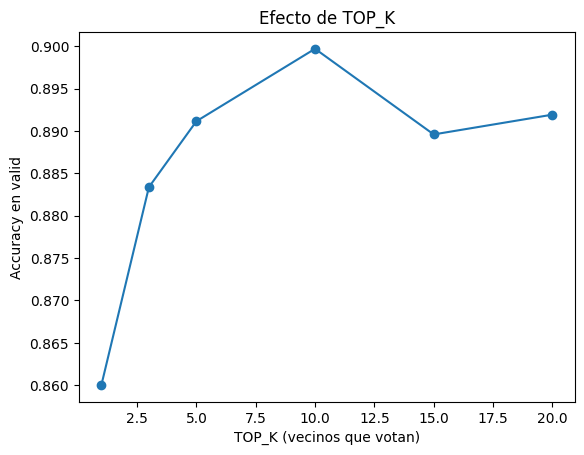

TOP_K elegido: 10


In [7]:
import matplotlib.pyplot as plt
# Accuracy de la raza predicha en valid según la cantidad de vecinos que votan
valores_k = [1, 3, 5, 10, 15, 20]
acc_k = pd.Series({k: evaluar("valid", k_voto=k)["acierto"].mean() for k in valores_k}, name="accuracy valid")
display(acc_k.round(3).to_frame())
plt.plot(acc_k.index, acc_k.values, marker="o")
plt.xlabel("TOP_K (vecinos que votan)"); plt.ylabel("Accuracy en valid"); plt.title("Efecto de TOP_K"); plt.show()

K_VOTO = int(acc_k.idxmax())
print("TOP_K elegido:", K_VOTO)

**Resultado.** Con 1 solo vecino la accuracy en `valid` es 86,0%: la predicción depende de una
única imagen y un vecino equivocado basta para fallar. Al aumentar los vecinos que votan sube hasta
**90,0% con TOP_K = 10** y luego baja levemente (89,0–89,2% con 15 y 20), porque empiezan a votar
imágenes menos parecidas. Se elige **TOP_K = 10**, que además coincide con la cantidad de vecinos
que muestra la app y con el k del NDCG@10.

### 5.4 Calibración del umbral (`SIMILARITY_THRESHOLD`)
Si el score de la raza ganadora (similitud media de los vecinos que la votaron) es bajo, la imagen
no se parece lo suficiente a ninguna raza y se responde `"unknown"`. El umbral se calibra en
**`valid`**: se toma el **percentil 5 del score de las predicciones correctas**, es decir, se
acepta rechazar como máximo el 5% de los aciertos. Después se mide qué pasa en `test`, en el
conjunto independiente y en las imágenes sin perro (que idealmente deberían rechazarse).

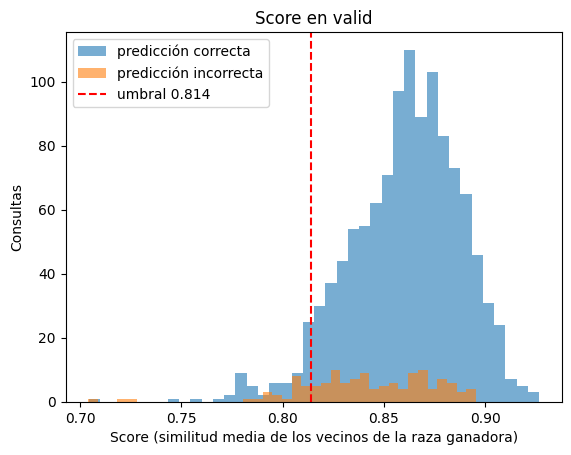

,conjunto,n,% unknown,accuracy (todas),accuracy (no rechazadas)
0,valid,1286,0.064,0.855,0.913
1,test,1287,0.077,0.831,0.901
2,independiente,162,0.562,0.364,0.831
3,sin_perro,19,1.000,NaN,NaN


Umbral calibrado (cosine): 0.814


In [8]:
r_val = evaluar("valid", k_voto=K_VOTO)
plt.hist(r_val.loc[r_val["acierto"], "score"], bins=40, alpha=0.6, label="predicción correcta")
plt.hist(r_val.loc[~r_val["acierto"], "score"], bins=40, alpha=0.6, label="predicción incorrecta")
UMBRAL = float(np.percentile(r_val.loc[r_val["acierto"], "score"], 5))
plt.axvline(UMBRAL, color="red", ls="--", label=f"umbral {UMBRAL:.3f}")
plt.xlabel("Score (similitud media de los vecinos de la raza ganadora)"); plt.ylabel("Consultas")
plt.legend(); plt.title("Score en valid"); plt.show()

filas = []
for nombre in ["valid", "test", "independiente", "sin_perro"]:
    r = evaluar(nombre, k_voto=K_VOTO, umbral=UMBRAL)
    rechazadas = r["pred"] == "unknown"
    filas.append({"conjunto": nombre, "n": len(r), "% unknown": rechazadas.mean(),
                  "accuracy (todas)": r["acierto"].mean() if nombre != "sin_perro" else None,
                  "accuracy (no rechazadas)": r.loc[~rechazadas, "acierto"].mean() if nombre != "sin_perro" else None})
display(pd.DataFrame(filas).round(3))
print(f"Umbral calibrado (cosine): {UMBRAL:.3f}")

**Resultado.** Con el umbral calibrado en `valid` (0,814, percentil 5 de las predicciones
correctas) se rechazan el 100% de las imágenes sin perro, pero también el 56% de las fotos reales
de perros del conjunto independiente: el cambio de dominio baja la similitud con la galería y
muchas fotos válidas quedan debajo del umbral. Además, el histograma muestra que las predicciones
incorrectas tienen scores casi tan altos como las correctas: el score no distingue errores entre
razas, sino imágenes muy distintas a la galería.

### Umbrales alternativos
Se comparan las distribuciones del score en `valid`, en fotos reales de perros (independiente) y
en imágenes sin perro, y se evalúan umbrales más permisivos. Todos los candidatos se calculan
**solo sobre `valid`** (percentiles 5, 2, 1 y 0,5 del score de las predicciones correctas); los
demás conjuntos únicamente muestran la consecuencia de cada elección.

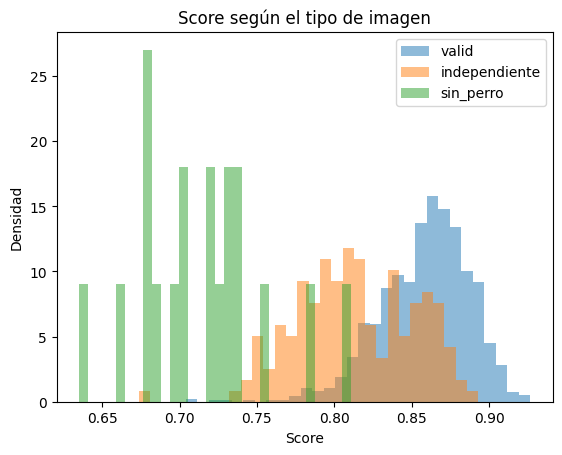

{'valid': (0.704, 0.862, 0.927), 'independiente': (0.674, 0.811, 0.893), 'sin_perro': (0.635, 0.718, 0.811)} (mín, mediana, máx)


,percentil (valid),umbral,% unknown valid,% unknown test,% unknown independiente,% unknown sin_perro
0,5.0,0.814,0.064,0.077,0.562,1.000
1,2.0,0.795,0.025,0.024,0.346,0.947
2,1.0,0.780,0.012,0.010,0.198,0.895
3,0.5,0.777,0.007,0.009,0.173,0.895


Umbral elegido: 0.78


In [9]:
# Distribución del score en los tres grupos (sin umbral)
scores = {n: evaluar(n, k_voto=K_VOTO)["score"] for n in ["valid", "independiente", "sin_perro"]}
for n, s in scores.items():
    plt.hist(s, bins=30, alpha=0.5, density=True, label=n)
plt.xlabel("Score"); plt.ylabel("Densidad"); plt.legend(); plt.title("Score según el tipo de imagen"); plt.show()
print({n: (round(s.min(), 3), round(s.median(), 3), round(s.max(), 3)) for n, s in scores.items()}, "(mín, mediana, máx)")

# Umbrales candidatos, todos calculados sobre las predicciones correctas de valid
correctas = r_val.loc[r_val["acierto"], "score"]
filas = []
for p in [5, 2, 1, 0.5]:
    u = float(np.percentile(correctas, p))
    fila = {"percentil (valid)": p, "umbral": round(u, 3)}
    for n in ["valid", "test", "independiente", "sin_perro"]:
        fila[f"% unknown {n}"] = round((evaluar(n, k_voto=K_VOTO, umbral=u)["pred"] == "unknown").mean(), 3)
    filas.append(fila)
display(pd.DataFrame(filas))
UMBRAL = round(float(np.percentile(correctas, 1)), 2)
print("Umbral elegido:", UMBRAL)

**Resultado.**
- Los scores se ordenan según qué tan parecida es la imagen a la galería: **sin perro** (mediana
  0,718) < **fotos reales de perros** (mediana 0,811) < **valid** (mediana 0,862). El umbral del
  percentil 5 (0,814) cae en el medio de las fotos reales, y por eso rechaza a más de la mitad.
- **Umbral elegido: percentil 1 de `valid`, `SIMILARITY_THRESHOLD = 0.78`.** Rechaza el 89,5% de
  las imágenes sin perro (17 de 19) y solo el 19,8% de las fotos reales de perros (frente al 56%
  del percentil 5), con un impacto mínimo en `test` (1%). Un umbral más permisivo (percentil 0,5)
  prácticamente no cambia los resultados; uno más estricto vuelve a rechazar muchas fotos reales.
- **Limitación:** el valor del umbral se calcula solo con `valid`, pero la elección entre los
  candidatos se apoyó en su efecto sobre el conjunto independiente y las imágenes sin perro, lo que
  implica una influencia leve del conjunto de evaluación en la decisión. Además, el score **no
  detecta errores entre razas** (las predicciones incorrectas de `valid` tienen scores similares a
  las correctas): solo identifica imágenes muy distintas a la galería.

### 5.5 Análisis de fallos
Razas con peor NDCG@10 en `test` y ejemplos de consultas mal clasificadas junto con sus 10 vecinos
más similares, para entender por qué falla la búsqueda.

Razas con peor NDCG@10 en test:


,ndcg,accuracy,n
raza,,,
Labradoodle,0.383,0.375,16
Bulldog,0.416,0.429,21
Lhasa,0.480,0.481,27
Chinese Crested,0.499,0.474,19
American Hairless,0.542,0.667,12
Boston Terrier,0.586,0.786,14
Cockapoo,0.614,0.824,17
Great Dane,0.617,0.762,21


raza               pred          
Lhasa              Shih-Tzu          10
Bulldog            Boston Terrier     8
Labradoodle        Cockapoo           4
Lhasa              Maltese            4
American Hairless  Mex Hairless       4
Bearded Collie     Lhasa              3
Malinois           Groenendael        3
Shih-Tzu           Lhasa              3
dtype: int64


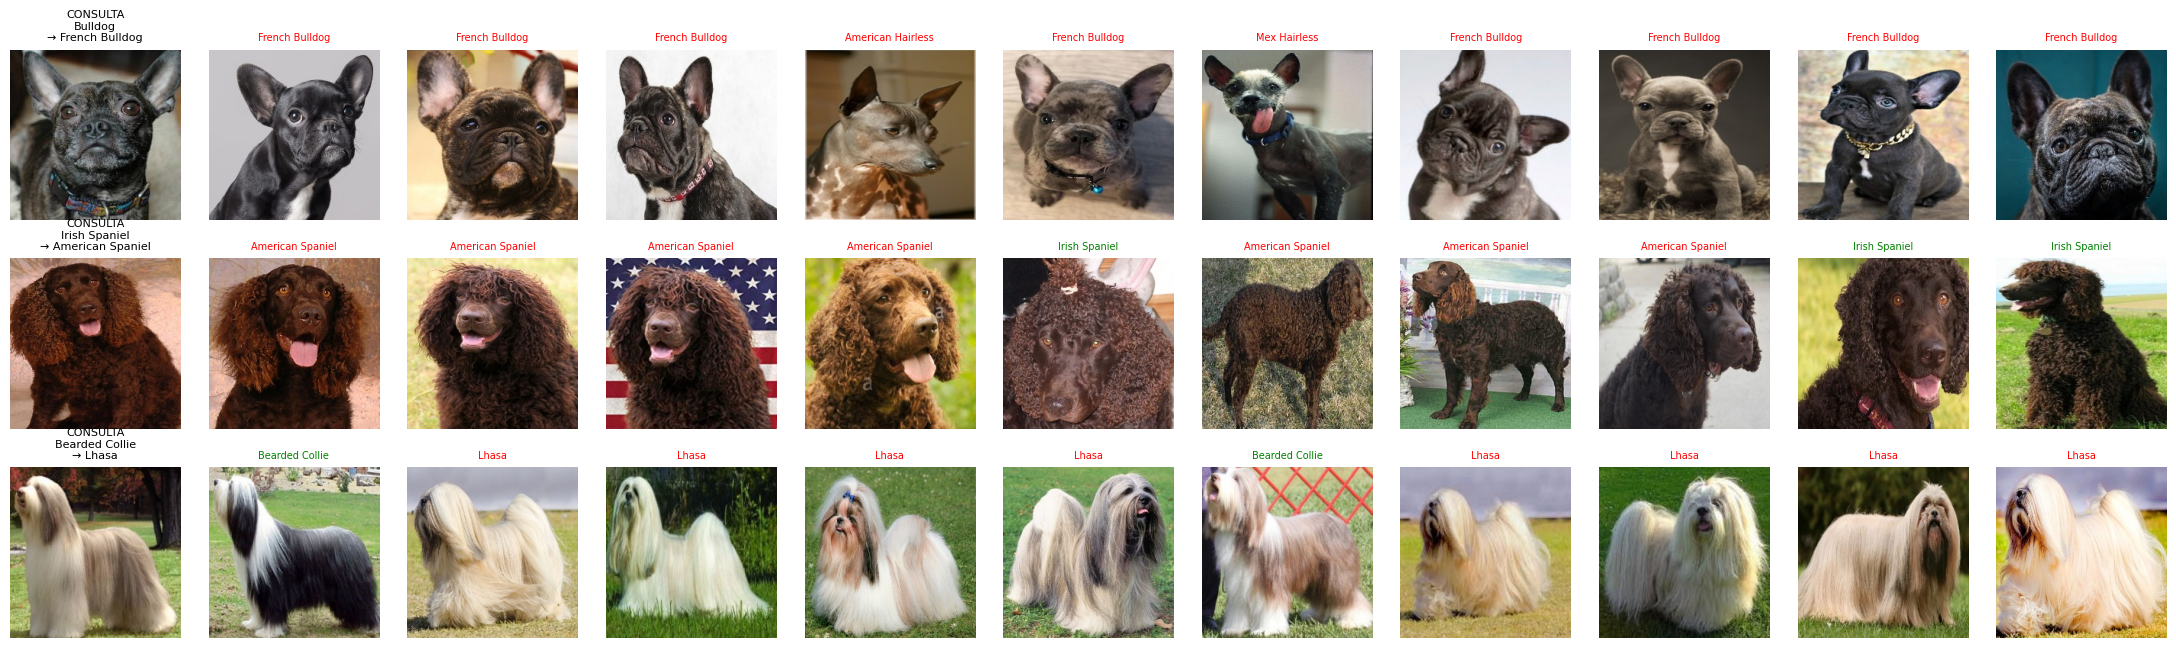

In [10]:
from PIL import Image

r_test = evaluar("test", k_voto=K_VOTO, umbral=UMBRAL)
por_raza = r_test.groupby("raza").agg(ndcg=("ndcg@10", "mean"), accuracy=("acierto", "mean"), n=("raza", "size"))
print("Razas con peor NDCG@10 en test:")
display(por_raza.sort_values("ndcg").head(8).round(3))

# Confusiones más frecuentes (raza real → raza predicha)
errores = r_test[~r_test["acierto"] & (r_test["pred"] != "unknown")]
print(errores.groupby(["raza", "pred"]).size().sort_values(ascending=False).head(8))

# 3 consultas fallidas con su top-10 (verde = misma raza, rojo = otra)
galeria = conjuntos["train"]
fig, ejes = plt.subplots(3, 11, figsize=(22, 6.5))
for fila_ejes, (i, f) in zip(ejes, errores.sample(3, random_state=1).iterrows()):
    fila_ejes[0].imshow(Image.open(conjuntos["test"].at[i, "ruta"]).convert("RGB"))
    fila_ejes[0].set_title(f"CONSULTA\n{f['raza']}\n→ {f['pred']}", fontsize=8)
    for eje, j in zip(fila_ejes[1:], f["top10"]):
        eje.imshow(Image.open(galeria.at[j, "ruta"]).convert("RGB"))
        eje.set_title(galeria.at[j, "raza"], fontsize=7,
                      color="green" if galeria.at[j, "raza"] == f["raza"] else "red")
    for eje in fila_ejes: eje.axis("off")
plt.tight_layout(); plt.show()

**Resultado.**
- Las razas con peor NDCG@10 en `test` son **Labradoodle (0,38), Bulldog (0,42), Lhasa (0,48),
  Chinese Crested (0,50) y American Hairless (0,54)**.
- Las confusiones más frecuentes coinciden con los pares anticipados en el EDA (sección 6.2 de la
  notebook 1): **Lhasa → Shih-Tzu (10)**, **Bulldog → Boston Terrier (8)**, Labradoodle → Cockapoo
  (4), Lhasa → Maltese (4), American Hairless → Mex Hairless (4) y Malinois → Groenendael (3).
- En los ejemplos visuales:
  - **Bulldog → French Bulldog:** la consulta etiquetada "Bulldog" es, a la vista, un Bulldog
    Francés, y sus 10 vecinos son Bulldogs Franceses. El error es del **etiquetado del dataset**
    (ruido ya observado en la carpeta "Bulldog"), no del buscador.
  - **Irish Spaniel → American Spaniel:** los vecinos de ambas razas son perros marrones de pelo
    rizado prácticamente indistinguibles. Es consistente con lo hallado en el control de calidad,
    donde la misma foto aparecía en las dos carpetas.
  - **Bearded Collie → Lhasa:** perros de pelo largo, lacio y claro; con fondo y pose similares,
    los embeddings de ImageNet los agrupan juntos.
- **Conclusión:** buena parte de los errores se explica por razas muy parecidas y por ruido de
  etiquetas del dataset. Un embedding entrenado específicamente para distinguir razas (Etapa 2)
  debería separar mejor algunos de estos pares.

## 6. Modelo A (obligatorio): fine-tuning de ResNet

Se ajusta una ResNet18 preentrenada en ImageNet, reemplazando la capa final por una de 70 salidas.
Se comparan **tres variantes** y se elige la de mejor accuracy en **`valid`**:

| Variante | Qué se entrena | Learning rate |
|---|---|---|
| **Feature extraction** | Solo la capa final (la red preentrenada queda congelada) | 1e-3 |
| **Fine-tuning** | Toda la red | 1e-4 en la red preentrenada, 1e-3 en la capa final |
| **Fine-tuning + class weights** | Toda la red, con más peso en la pérdida a las razas con menos imágenes | ídem |

Hiperparámetros comunes: optimizador AdamW (weight decay 1e-4), scheduler coseno, batch size 64,
label smoothing 0,1, data augmentation en `train` y early stopping (paciencia 3) guardando el mejor
modelo según accuracy en `valid`. Máximo 10 épocas (8 en feature extraction).
Los *learning rates* diferenciados evitan "borrar" lo que la red ya aprendió en ImageNet: la parte
preentrenada se ajusta despacio y la capa nueva, que arranca de cero, más rápido.

In [11]:
import json, shutil
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
RUTA_A = classifier.checkpoints["resnet18_finetuned"]  # models/resnet18_finetuned.pth (la usa la app)

def cargar_historial(ruta_checkpoint):
    return json.loads((settings.output_path / f"historial_{Path(ruta_checkpoint).stem}.json").read_text())

def evaluar_checkpoint(modelo, ruta, rutas=None, razas=None):
    """Evalúa un checkpoint concreto (por defecto sobre test) y restaura la ruta original."""
    original = classifier.checkpoints[modelo]
    classifier.checkpoints[modelo] = Path(ruta); classifier._loaded.pop(modelo, None)
    classifier.set_active_model(modelo)
    try:
        return classifier.evaluate_classifier(rutas, razas)
    finally:
        classifier.checkpoints[modelo] = original; classifier._loaded.pop(modelo, None)

# Tres variantes del Modelo A (cada una guarda su mejor checkpoint según valid)
classifier.set_active_model("resnet18_finetuned")
VARIANTES_A = {
    "feature extraction": (settings.model_path / "resnet18_feature_extraction.pth",
                           dict(estrategia="feature_extraction", epocas=8)),
    "fine-tuning": (RUTA_A, dict(estrategia="fine_tuning")),
    "fine-tuning + class weights": (settings.model_path / "resnet18_ft_class_weights.pth",
                                    dict(estrategia="fine_tuning", class_weights=True)),
}
for nombre, (ruta, cambios) in VARIANTES_A.items():
    print(f"\n===== {nombre} =====")
    classifier.train_classifier(ruta_checkpoint=ruta, **cambios)


===== feature extraction =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 2.8127, 'acc_train': 0.4769, 'loss_valid': 1.684, 'acc_valid': 0.8033, 'segundos': 17.4}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 1.6569, 'acc_train': 0.7822, 'loss_valid': 1.3964, 'acc_valid': 0.8499, 'segundos': 12.3}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 1.4613, 'acc_train': 0.831, 'loss_valid': 1.3319, 'acc_valid': 0.8663, 'segundos': 12.4}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 1.3931, 'acc_train': 0.8514, 'loss_valid': 1.3071, 'acc_valid': 0.8585, 'segundos': 12.3}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 1.3587, 'acc_train': 0.8582, 'loss_valid': 1.2971, 'acc_valid': 0.8577, 'segundos': 12.5}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 1.3328, 'acc_train': 0.8722, 'loss_valid': 1.2796, 'acc_valid': 0.8686, 'segundos': 12.5}
INFO:lib.services.classi


===== fine-tuning =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 2.1405, 'acc_train': 0.6274, 'loss_valid': 1.3047, 'acc_valid': 0.8655, 'segundos': 13.7}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 1.2376, 'acc_train': 0.8799, 'loss_valid': 1.2185, 'acc_valid': 0.8857, 'segundos': 13.8}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 1.1101, 'acc_train': 0.9242, 'loss_valid': 1.1676, 'acc_valid': 0.8935, 'segundos': 13.4}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 1.0272, 'acc_train': 0.95, 'loss_valid': 1.1422, 'acc_valid': 0.8974, 'segundos': 13.4}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 0.972, 'acc_train': 0.9667, 'loss_valid': 1.1308, 'acc_valid': 0.9005, 'segundos': 13.7}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 0.9378, 'acc_train': 0.9762, 'loss_valid': 1.1157, 'acc_valid': 0.9036, 'segundos': 13.8}
INFO:lib.services.classif


===== fine-tuning + class weights =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 2.1678, 'acc_train': 0.6282, 'loss_valid': 1.3318, 'acc_valid': 0.8561, 'segundos': 13.9}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 1.2574, 'acc_train': 0.8784, 'loss_valid': 1.2195, 'acc_valid': 0.881, 'segundos': 13.9}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 1.127, 'acc_train': 0.9228, 'loss_valid': 1.1975, 'acc_valid': 0.8919, 'segundos': 13.8}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 1.0405, 'acc_train': 0.9523, 'loss_valid': 1.1448, 'acc_valid': 0.9106, 'segundos': 13.7}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 0.9875, 'acc_train': 0.9695, 'loss_valid': 1.1432, 'acc_valid': 0.8958, 'segundos': 13.8}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 0.9508, 'acc_train': 0.9778, 'loss_valid': 1.1263, 'acc_valid': 0.9028, 'segundos': 14.1}
INFO:lib.services.classi

**Resultado.**
- Con GPU, cada época tarda ≈14–15 segundos: las tres variantes se entrenan en menos de 6 minutos.
- **Feature extraction** alcanza 87,1% de accuracy en `valid` entrenando solo la capa final: las
  características aprendidas en ImageNet ya distinguen bien las razas.
- **Fine-tuning** (toda la red con learning rates diferenciados) sube a **91,0%**, casi 4 puntos
  más: ajustar la red preentrenada a nuestras razas aporta.
- **Fine-tuning + class weights** llega a 91,1% (el early stopping lo detiene en la época 7): la
  diferencia con el fine-tuning sin pesos es de 1 imagen sobre 1.286, dentro del ruido. Con un
  desbalance moderado (≈3:1), compensar las clases no mejora el resultado de forma apreciable.
- **Overfitting moderado en el fine-tuning:** la accuracy de `train` llega a ≈98–99% mientras la
  de `valid` se estabiliza en ≈90–91% desde la época 4. La loss de `valid` no aumenta, por lo que
  el sobreajuste está controlado (augmentation, label smoothing y early stopping, que conserva la
  mejor época). En feature extraction no hay sobreajuste: train y valid evolucionan juntas.

In [12]:
# Comparación en valid (criterio de elección) y tiempo de entrenamiento
comparacion_a = pd.DataFrame([{
    "variante": nombre,
    "mejor acc valid": cargar_historial(ruta)["mejor_acc_valid"],
    "épocas": len(cargar_historial(ruta)["historial"]),
    "minutos": round(sum(h["segundos"] for h in cargar_historial(ruta)["historial"]) / 60, 1),
} for nombre, (ruta, _) in VARIANTES_A.items()]).set_index("variante")
display(comparacion_a.round(4))

# La variante ganadora queda como checkpoint del Modelo A que usa la app
ganadora = comparacion_a["mejor acc valid"].idxmax()
ruta_ganadora = VARIANTES_A[ganadora][0]
if Path(ruta_ganadora) != RUTA_A:
    shutil.copy(ruta_ganadora, RUTA_A)
print("Variante elegida:", ganadora)

# Métricas finales del Modelo A sobre test
metrics_a = evaluar_checkpoint("resnet18_finetuned", RUTA_A)
ev_a = classifier.ultima_evaluacion
pd.Series(metrics_a).round(4)

,mejor acc valid,épocas,minutos
variante,,,
feature extraction,0.8709,8,1.7
fine-tuning,0.9098,10,2.3
fine-tuning + class weights,0.9106,7,1.6


Variante elegida: fine-tuning + class weights


accuracy       0.8982
precision      0.9037
recall         0.8987
specificity    0.9985
f1             0.8979
dtype: float64

**Resultado.**
- **Variante elegida: fine-tuning + class weights** (mayor accuracy en `valid`, 0,9106). Su
  diferencia con el fine-tuning sin pesos es de 1 imagen, así que ambas son equivalentes; se
  mantiene el criterio fijado de antemano (mejor accuracy en `valid`). Este checkpoint queda como
  `models/resnet18_finetuned.pth`, el que usa la app.
- **Métricas en `test` (macro):** accuracy **89,8%**, precision 90,4%, recall 89,9%, F1 89,8% y
  specificity 99,85%.
- La **specificity** es tan alta porque se calcula *one-vs-rest*: para cada raza, casi todas las
  imágenes son de las otras 69 razas y el modelo las descarta correctamente, así que esa métrica
  siempre queda cerca de 1 con muchas clases. Las métricas informativas son precision, recall y F1.
- Frente a la búsqueda por similitud con el baseline (accuracy 88,7% en `test`), el clasificador
  entrenado mejora 1,1 puntos.

### Curvas de entrenamiento, matriz de confusión y razas con peor desempeño (Modelo A)
Curvas de loss y accuracy en `train` (línea llena) y `valid` (punteada) de las tres variantes, para
ver si hay *overfitting* (train sigue mejorando mientras valid se estanca o empeora). Después, la
matriz de confusión normalizada del modelo elegido sobre `test`, los pares de razas más confundidos
y las razas con peor F1.

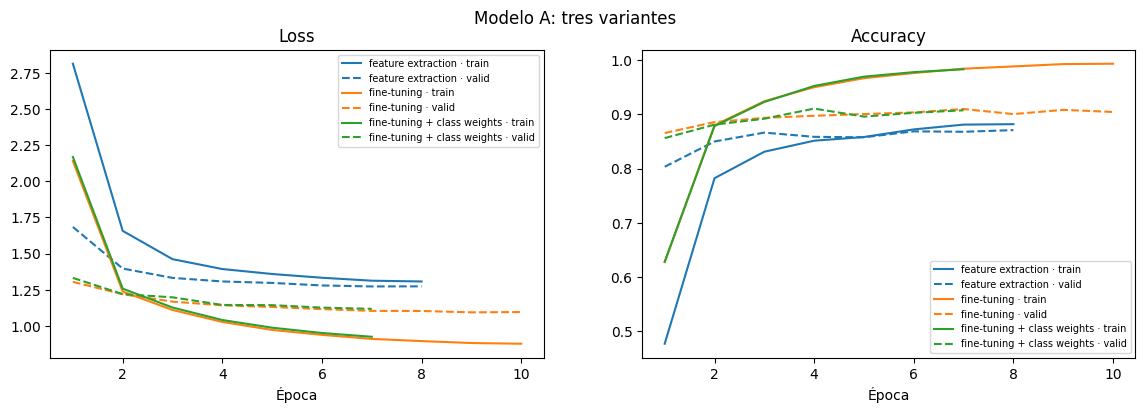

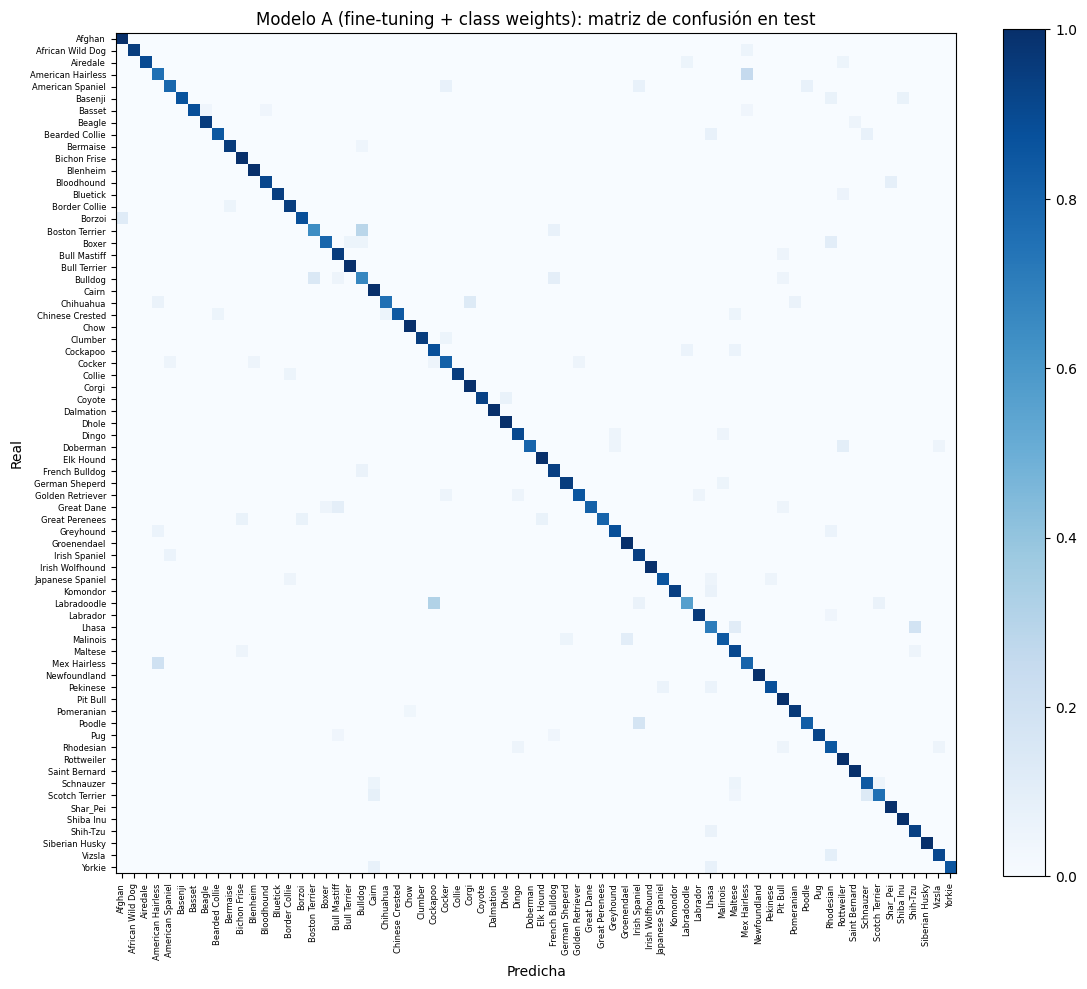

,real,predicha,proporción,casos
0,Labradoodle,Cockapoo,0.312,5
1,Boston Terrier,Bulldog,0.286,4
2,American Hairless,Mex Hairless,0.250,3
3,Mex Hairless,American Hairless,0.200,3
4,Lhasa,Shih-Tzu,0.185,5
5,Poodle,Irish Spaniel,0.176,3
6,Bulldog,Boston Terrier,0.143,3
7,Scotch Terrier,Schnauzer,0.125,3
8,Chihuahua,Corgi,0.125,2
9,Borzoi,Afghan,0.118,2


Razas con peor F1 en test:


,precision,recall,f1,n
Bulldog,0.667,0.667,0.667,21
Labradoodle,0.818,0.562,0.667,16
Boston Terrier,0.750,0.643,0.692,14
American Hairless,0.643,0.750,0.692,12
Lhasa,0.731,0.704,0.717,27
Mex Hairless,0.706,0.800,0.750,15
Cockapoo,0.714,0.882,0.789,17
Rhodesian,0.739,0.850,0.791,20


In [13]:
def graficar_curvas(registros, titulo):
    fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
    for etiqueta, reg in registros.items():
        h = pd.DataFrame(reg["historial"])
        linea, = ejes[0].plot(h["epoca"], h["loss_train"], label=f"{etiqueta} · train")
        ejes[0].plot(h["epoca"], h["loss_valid"], ls="--", color=linea.get_color(), label=f"{etiqueta} · valid")
        ejes[1].plot(h["epoca"], h["acc_train"], color=linea.get_color(), label=f"{etiqueta} · train")
        ejes[1].plot(h["epoca"], h["acc_valid"], ls="--", color=linea.get_color(), label=f"{etiqueta} · valid")
    for eje, nombre in zip(ejes, ["Loss", "Accuracy"]):
        eje.set_xlabel("Época"); eje.set_title(nombre); eje.legend(fontsize=7)
    plt.suptitle(titulo); plt.show()

def matriz_y_confusiones(ev, titulo, top=10):
    """Matriz de confusión normalizada por fila y los pares (real → predicha) más confundidos."""
    m = ev["matriz"].astype(float)
    norm = m / m.sum(axis=1, keepdims=True).clip(min=1)
    plt.figure(figsize=(12, 11)); plt.imshow(norm, cmap="Blues", vmin=0, vmax=1); plt.colorbar(fraction=0.046)
    plt.xticks(range(len(ev["razas"])), ev["razas"], rotation=90, fontsize=6)
    plt.yticks(range(len(ev["razas"])), ev["razas"], fontsize=6)
    plt.xlabel("Predicha"); plt.ylabel("Real"); plt.title(titulo); plt.show()
    fuera = norm.copy(); np.fill_diagonal(fuera, 0)
    orden = np.argsort(-fuera, axis=None)[:top]
    return pd.DataFrame([{"real": ev["razas"][i], "predicha": ev["razas"][j],
                          "proporción": round(fuera[i, j], 3), "casos": int(m[i, j])}
                         for i, j in zip(*np.unravel_index(orden, fuera.shape)) if m[i, j] > 0])

def metricas_por_raza(ev):
    m = ev["matriz"]; tp = np.diag(m)
    precision = tp / m.sum(axis=0).clip(min=1); recall = tp / m.sum(axis=1).clip(min=1)
    f1 = 2 * precision * recall / (precision + recall).clip(min=1e-12)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "n": m.sum(axis=1)}, index=ev["razas"])

graficar_curvas({n: cargar_historial(r) for n, (r, _) in VARIANTES_A.items()}, "Modelo A: tres variantes")
display(matriz_y_confusiones(ev_a, f"Modelo A ({ganadora}): matriz de confusión en test"))
print("Razas con peor F1 en test:")
display(metricas_por_raza(ev_a).sort_values("f1").head(8).round(3))

**Resultado.**
- **Curvas:** las dos variantes de fine-tuning se comportan casi igual: la accuracy de `train`
  llega a ≈98–99% y la de `valid` se estabiliza en ≈90–91% desde la época 4. Hay un sobreajuste
  moderado, pero la loss de `valid` no empeora, así que no es dañino. En feature extraction las
  curvas de train y valid van juntas (sin sobreajuste), pero se estancan más abajo (≈87%): con la
  red congelada el modelo tiene menos capacidad de adaptarse.
- **Pares más confundidos:** Labradoodle → Cockapoo (31% de los Labradoodle), Boston Terrier →
  Bulldog (29%), American Hairless ↔ Mex Hairless en ambos sentidos (25% y 20%), Lhasa → Shih-Tzu
  (19%), Poodle → Irish Spaniel (18%) y Bulldog → Boston Terrier (14%). Son los mismos pares que se
  anticiparon en el EDA y que fallaban en la búsqueda por similitud (Etapa 1).
- **Razas con peor F1:** Bulldog (0,67), Labradoodle (0,67), Boston Terrier (0,69), American
  Hairless (0,69) y Lhasa (0,72). En todos los casos el error es con una raza visualmente muy
  parecida: cruces con caniche de pelo rizado (Labradoodle/Cockapoo), perros pequeños de pelo
  largo (Lhasa/Shih-Tzu) o perros sin pelo (American Hairless/Mex Hairless).
- La confusión **Bulldog ↔ Boston Terrier en ambos sentidos** es consistente con el ruido de
  etiquetas observado en la carpeta "Bulldog" (fotos de aspecto Boston Terrier o Bulldog Francés):
  el modelo no puede aprender una frontera limpia entre clases cuyas etiquetas se mezclan.

## 7. Modelo B (obligatorio): CNN propia

CNN diseñada desde cero (`src/lib/models/clasificadores.py`, clase `CNNPropia`), sin pesos
preentrenados:
- **Bloques convolucionales:** cada bloque tiene dos convoluciones 3×3 con BatchNorm y ReLU, y un
  MaxPool que reduce la imagen a la mitad; la cantidad de filtros se duplica en cada bloque
  (32 → 64 → 128 → 256 → 512), para pasar de detalles simples (bordes, texturas) a patrones más
  complejos (orejas, hocicos, pelaje).
- **BatchNorm** estabiliza y acelera el entrenamiento desde cero.
- **Global average pooling:** resume cada filtro en un número; tiene muchos menos parámetros que
  aplanar la imagen y reduce el sobreajuste.
- **Capa de embedding de 512** (= `EMBEDDING_DIM`) antes del clasificador, que se usa en la
  búsqueda por similitud, y **Dropout 0,3** antes de la capa final.

Se entrenan tres experimentos (máximo 30 épocas, early stopping con paciencia 6, AdamW con lr 1e-3,
scheduler coseno, label smoothing 0,1) y se elige el de mejor accuracy en `valid`:

| Experimento | Bloques | Augmentation | Objetivo |
|---|---|---|---|
| E1 | 4 (32→256) | No | Línea de base sin augmentation |
| E2 | 4 (32→256) | Sí | Medir el efecto de la augmentation |
| E3 | 5 (32→512) | Sí | Medir el efecto de más profundidad |

In [14]:
from lib.models.clasificadores import CNNPropia

RUTA_B = classifier.checkpoints["cnn_custom"]  # models/cnn_custom.pth (la usa la app)
classifier.set_active_model("cnn_custom")
EXPERIMENTOS_B = {
    "E1: 4 bloques, sin augmentation": (settings.model_path / "cnn_e1.pth",
                                        dict(canales=(32, 64, 128, 256), aumentacion=False)),
    "E2: 4 bloques, con augmentation": (settings.model_path / "cnn_e2.pth",
                                        dict(canales=(32, 64, 128, 256), aumentacion=True)),
    "E3: 5 bloques, con augmentation": (settings.model_path / "cnn_e3.pth",
                                        dict(canales=(32, 64, 128, 256, 512), aumentacion=True)),
}
for nombre, (ruta, cambios) in EXPERIMENTOS_B.items():
    print(f"\n===== {nombre} =====")
    classifier.train_classifier(ruta_checkpoint=ruta, **cambios)


===== E1: 4 bloques, sin augmentation =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 4.0138, 'acc_train': 0.0655, 'loss_valid': 4.6861, 'acc_valid': 0.0319, 'segundos': 22.2}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 3.7126, 'acc_train': 0.1086, 'loss_valid': 3.7284, 'acc_valid': 0.1112, 'segundos': 22.5}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 3.5088, 'acc_train': 0.1521, 'loss_valid': 4.0318, 'acc_valid': 0.0918, 'segundos': 21.9}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 3.3459, 'acc_train': 0.1908, 'loss_valid': 3.7795, 'acc_valid': 0.1306, 'segundos': 21.9}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 3.2046, 'acc_train': 0.2298, 'loss_valid': 3.416, 'acc_valid': 0.203, 'segundos': 22.2}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 3.0732, 'acc_train': 0.2621, 'loss_valid': 3.2921, 'acc_valid': 0.2208, 'segundos': 21.9}
INFO:lib.services.classi


===== E2: 4 bloques, con augmentation =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 4.1348, 'acc_train': 0.0402, 'loss_valid': 4.0143, 'acc_valid': 0.0599, 'segundos': 21.9}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 3.9217, 'acc_train': 0.076, 'loss_valid': 3.8692, 'acc_valid': 0.0832, 'segundos': 21.9}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 3.7714, 'acc_train': 0.0998, 'loss_valid': 3.8698, 'acc_valid': 0.1034, 'segundos': 22.0}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 3.6228, 'acc_train': 0.1338, 'loss_valid': 3.7539, 'acc_valid': 0.1236, 'segundos': 22.0}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 3.5014, 'acc_train': 0.1551, 'loss_valid': 3.6089, 'acc_valid': 0.1291, 'segundos': 22.1}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 3.3518, 'acc_train': 0.1986, 'loss_valid': 3.5101, 'acc_valid': 0.1649, 'segundos': 22.0}
INFO:lib.services.class


===== E3: 5 bloques, con augmentation =====


INFO:lib.services.classifier_service:Época 1: {'epoca': 1, 'loss_train': 4.0896, 'acc_train': 0.0457, 'loss_valid': 4.0336, 'acc_valid': 0.0552, 'segundos': 24.1}
INFO:lib.services.classifier_service:Época 2: {'epoca': 2, 'loss_train': 3.8668, 'acc_train': 0.0858, 'loss_valid': 4.1621, 'acc_valid': 0.0754, 'segundos': 24.1}
INFO:lib.services.classifier_service:Época 3: {'epoca': 3, 'loss_train': 3.6882, 'acc_train': 0.1113, 'loss_valid': 3.7287, 'acc_valid': 0.1283, 'segundos': 24.1}
INFO:lib.services.classifier_service:Época 4: {'epoca': 4, 'loss_train': 3.5399, 'acc_train': 0.1461, 'loss_valid': 3.6193, 'acc_valid': 0.1532, 'segundos': 24.1}
INFO:lib.services.classifier_service:Época 5: {'epoca': 5, 'loss_train': 3.3958, 'acc_train': 0.1775, 'loss_valid': 3.3994, 'acc_valid': 0.2053, 'segundos': 24.3}
INFO:lib.services.classifier_service:Época 6: {'epoca': 6, 'loss_train': 3.2587, 'acc_train': 0.2143, 'loss_valid': 3.565, 'acc_valid': 0.1804, 'segundos': 24.5}
INFO:lib.services.class

**Resultado.** Cada época tarda ≈21–24 segundos; los tres experimentos se entrenan en ≈34 minutos.
Las tres CNN aprenden lentamente desde cero: arrancan en ≈4–6% de accuracy (el azar es 1/70 ≈ 1,4%)
y siguen mejorando al llegar a la época 30, sin que actúe el early stopping.

In [15]:
def contar_parametros(ruta):
    return sum(p.numel() for p in torch.load(ruta, map_location="cpu", weights_only=False).parameters())

tabla_b = pd.DataFrame([{
    "experimento": nombre,
    "parámetros (M)": round(contar_parametros(ruta) / 1e6, 2),
    "mejor acc valid": cargar_historial(ruta)["mejor_acc_valid"],
    "acc train (época final)": cargar_historial(ruta)["historial"][-1]["acc_train"],
    "épocas": len(cargar_historial(ruta)["historial"]),
    "minutos": round(sum(h["segundos"] for h in cargar_historial(ruta)["historial"]) / 60, 1),
} for nombre, (ruta, _) in EXPERIMENTOS_B.items()]).set_index("experimento")
display(tabla_b.round(4))

# El mejor experimento queda como checkpoint del Modelo B que usa la app
ganador_b = tabla_b["mejor acc valid"].idxmax()
shutil.copy(EXPERIMENTOS_B[ganador_b][0], RUTA_B)
print("Experimento elegido:", ganador_b)

metrics_b = evaluar_checkpoint("cnn_custom", RUTA_B)
ev_b = classifier.ultima_evaluacion
pd.Series(metrics_b).round(4)

,parámetros (M),mejor acc valid,acc train (época final),épocas,minutos
experimento,,,,,
"E1: 4 bloques, sin augmentation",1.34,0.6104,0.9133,30,11.0
"E2: 4 bloques, con augmentation",1.34,0.5560,0.6277,30,11.0
"E3: 5 bloques, con augmentation",5.01,0.6680,0.8005,30,12.2


Experimento elegido: E3: 5 bloques, con augmentation


accuracy       0.6542
precision      0.6733
recall         0.6521
specificity    0.9950
f1             0.6525
dtype: float64

**Resultado: tabla de experimentos.**

| Experimento | Parámetros | Acc. valid | Acc. train | Lectura |
|---|---|---|---|---|
| E1: 4 bloques, sin augmentation | 1,34 M | 61,0% | 91,3% | Sobreajuste fuerte: memoriza `train` (30 puntos de diferencia con valid) |
| E2: 4 bloques, con augmentation | 1,34 M | 55,6% | 62,8% | La augmentation reduce el sobreajuste, pero la red es chica para aprovecharla |
| E3: 5 bloques, con augmentation | 5,01 M | **66,8%** | 80,1% | Más capacidad + augmentation: mejor resultado y sobreajuste moderado |

- **Qué funcionó y qué no:** la augmentation sola (E2) empeoró la accuracy, porque hace la tarea
  más difícil para una red de poca capacidad; combinada con un bloque más (E3) dio el mejor
  resultado. Sin augmentation (E1) la red memoriza las imágenes de entrenamiento.
- **Experimento elegido: E3**, que queda como `models/cnn_custom.pth` (el que usa la app).
- **Métricas en `test` (macro):** accuracy **65,4%**, precision 67,3%, recall 65,2%, F1 65,3% y
  specificity 99,5%.
- **Por qué rinde ≈24 puntos menos que el Modelo A (89,8%):**
  1. **Sin preentrenamiento:** la ResNet ya aprendió a reconocer formas, texturas y partes de
     animales con 1,2 millones de imágenes de ImageNet; la CNN propia aprende todo desde cero con
     solo ≈86 imágenes por raza.
  2. **Tarea de grano fino:** distinguir 70 razas parecidas requiere detalles sutiles (pelaje,
     forma del hocico) que se aprenden con muchos más datos.
  3. **Capacidad y entrenamiento:** 5 M de parámetros contra 11 M de la ResNet18, y 30 épocas no
     alcanzan para converger (las curvas siguen subiendo). Más épocas mejorarían algo el resultado,
     pero sin acercarse al Modelo A.

### Curvas de entrenamiento, matriz de confusión y razas con peor desempeño (Modelo B)
Mismo análisis que para el Modelo A, con los tres experimentos de la CNN propia.

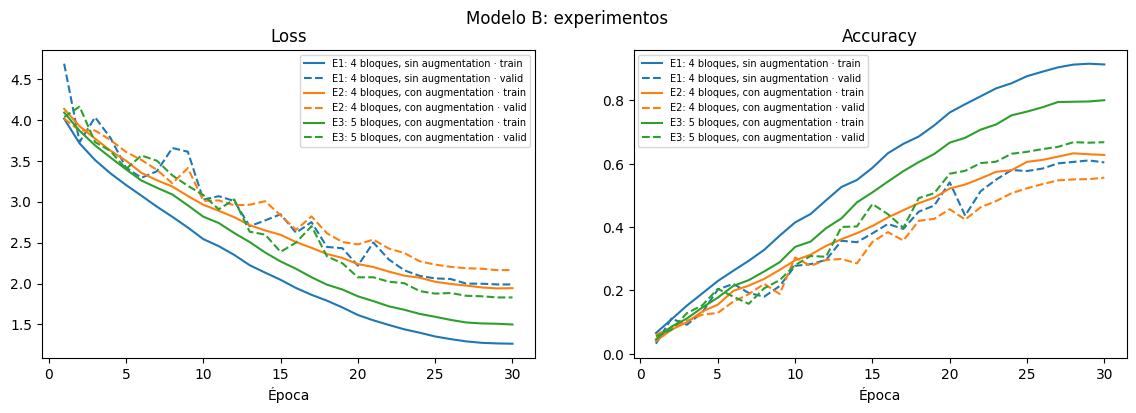

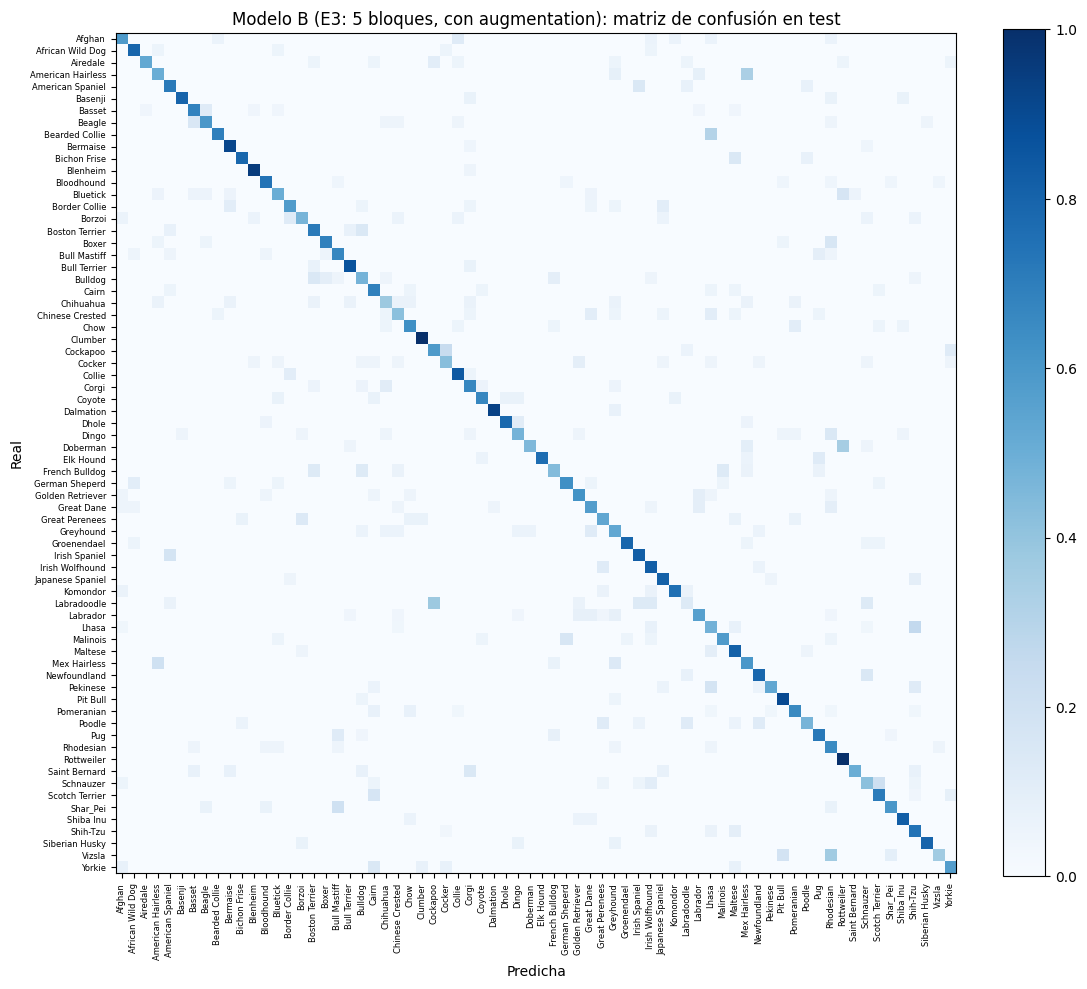

,real,predicha,proporción,casos
0,Labradoodle,Cockapoo,0.375,6
1,Vizsla,Rhodesian,0.364,4
2,Doberman,Rottweiler,0.350,7
3,American Hairless,Mex Hairless,0.333,4
4,Bearded Collie,Lhasa,0.308,4
5,Lhasa,Shih-Tzu,0.259,7
6,Cockapoo,Cocker,0.235,4
7,Schnauzer,Scotch Terrier,0.211,4
8,Mex Hairless,American Hairless,0.200,3
9,Shar_Pei,Bull Mastiff,0.200,3


Razas con peor F1 en test:


,precision,recall,f1,n
Labradoodle,0.222,0.125,0.160,16
Chihuahua,0.429,0.375,0.400,16
Schnauzer,0.444,0.421,0.432,19
Lhasa,0.406,0.481,0.441,27
Chinese Crested,0.471,0.421,0.444,19
Greyhound,0.391,0.529,0.450,17
Vizsla,0.667,0.364,0.471,11
Rhodesian,0.371,0.650,0.473,20


In [17]:
graficar_curvas({n: cargar_historial(r) for n, (r, _) in EXPERIMENTOS_B.items()}, "Modelo B: experimentos")
display(matriz_y_confusiones(ev_b, f"Modelo B ({ganador_b}): matriz de confusión en test"))
print("Razas con peor F1 en test:")
display(metricas_por_raza(ev_b).sort_values("f1").head(8).round(3))

**Resultado.**
- **Curvas:** en E1 la accuracy de `train` sube hasta ≈91% mientras la de `valid` queda en ≈61%:
  sobreajuste claro. Con augmentation (E2 y E3) las curvas de train y valid quedan mucho más cerca.
  Las curvas de `valid` son irregulares (saltos de época a época), algo habitual al entrenar desde
  cero. En E3 las dos curvas siguen subiendo en la época 30: el modelo todavía no convergió.
- **Pares más confundidos:** Labradoodle → Cockapoo (38%), Vizsla → Rhodesian (36%), Doberman →
  Rottweiler (35%), American Hairless → Mex Hairless (33%), Bearded Collie → Lhasa (31%) y
  Lhasa → Shih-Tzu (26%).
- **Razas con peor F1:** Labradoodle (0,16), Chihuahua (0,40), Schnauzer (0,43), Lhasa (0,44),
  Chinese Crested (0,44) y Greyhound (0,45).
- **Diferencia con el Modelo A:** además de los pares difíciles que también confunde la ResNet,
  la CNN propia confunde razas que comparten **color y silueta general** pero se distinguen por
  detalles: Doberman/Rottweiler (negro y fuego), Vizsla/Rhodesian (pelaje rojizo corto),
  Schnauzer/Scotch Terrier (negros de pelo duro). Esto sugiere que la CNN propia se apoya sobre
  todo en el color y la forma global, mientras que la ResNet preentrenada capta rasgos más finos.

## 8. Evaluación sobre el conjunto independiente

Se evalúan ambos clasificadores sobre las 162 imágenes de raza del conjunto independiente (fotos
de otras fuentes, 56 razas) y se comparan con `test`. Como son ≈3 imágenes por raza, el F1 macro
de este conjunto es poco estable; la accuracy es la métrica más confiable. Se separa por fuente
(Oxford-IIIT Pet / Stanford Dogs).

In [18]:
ind = conjuntos["independiente"]
filas = []
for nombre, modelo, ruta, met_test in [("Modelo A", "resnet18_finetuned", RUTA_A, metrics_a),
                                       ("Modelo B", "cnn_custom", RUTA_B, metrics_b)]:
    met_ind = evaluar_checkpoint(modelo, ruta, list(ind["ruta"]), list(ind["raza"]))
    ev = classifier.ultima_evaluacion
    acierto = np.array(ev["razas"])[ev["y_pred"]] == ind["raza"].to_numpy()
    filas.append({"modelo": nombre,
                  "accuracy test": met_test["accuracy"], "accuracy independiente": met_ind["accuracy"],
                  "F1 test": met_test["f1"], "F1 independiente": met_ind["f1"],
                  "accuracy Oxford": acierto[(ind["fuente"] == "Oxford-IIIT Pet").to_numpy()].mean(),
                  "accuracy Stanford": acierto[(ind["fuente"] == "Stanford Dogs").to_numpy()].mean()})
    if nombre == "Modelo A":
        ev_ind_a = ev  # se usa en el análisis de errores
tabla_indep = pd.DataFrame(filas).set_index("modelo")
display(tabla_indep.round(3))

,accuracy test,accuracy independiente,F1 test,F1 independiente,accuracy Oxford,accuracy Stanford
modelo,,,,,,
Modelo A,0.898,0.599,0.898,0.603,0.667,0.573
Modelo B,0.654,0.173,0.653,0.174,0.156,0.179


**Resultado.**
- **Modelo A:** 89,8% de accuracy en `test`, pero **59,9% en el conjunto independiente** (Oxford
  66,7%, Stanford 57,3%). Es una caída mucho mayor que la de la búsqueda por similitud con el
  baseline, que sobre las mismas fotos obtenía 77,8% (sección 5.2): el modelo entrenado generaliza
  peor fuera del dataset que la ResNet de ImageNet sin entrenar.
- **Modelo B:** 65,4% en `test` y **17,3% en el independiente**. La CNN propia, entrenada desde cero
  con pocas imágenes, prácticamente no generaliza a fotos de otras fuentes.
- El F1 del independiente (0,60 y 0,17) acompaña a la accuracy, pero con ≈3 imágenes por raza es
  poco estable.

### ¿Por qué cae tanto en el conjunto independiente?
Hipótesis: todas las imágenes del dataset son cuadradas, por lo que durante el entrenamiento el
modelo nunca vio las bandas de relleno; las fotos del conjunto independiente son rectangulares y,
al rellenarlas, el perro queda más chico y rodeado de gris. Se evalúa el Modelo A sobre el conjunto
independiente con tres formas de llevar la imagen a cuadrado (en el dataset las tres son idénticas).

In [30]:
import cv2
from lib.preprocesamiento import a_tensor, a_rgb_cuadrada

def recorte_central(bgr, n):
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB); h, w = rgb.shape[:2]; l = min(h, w)
    y, x = (h - l) // 2, (w - l) // 2
    return cv2.resize(rgb[y:y + l, x:x + l], (n, n), interpolation=cv2.INTER_AREA)

def resize_directo(bgr, n):
    return cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), (n, n), interpolation=cv2.INTER_AREA)

dev = "cuda" if torch.cuda.is_available() else "cpu"
red_a = torch.load(RUTA_A, map_location="cpu", weights_only=False).to(dev).eval()
razas_a = np.array(red_a.razas)
for nombre, f in [("relleno (actual)", a_rgb_cuadrada), ("recorte central", recorte_central), ("resize directo", resize_directo)]:
    x = torch.stack([a_tensor(f(leer_imagen(r), settings.image_size)) for r in ind["ruta"]]).to(dev)
    with torch.no_grad():
        pred = razas_a[red_a(x).argmax(1).cpu().numpy()]
    print(f"{nombre:18s} accuracy independiente: {(pred == ind['raza'].to_numpy()).mean():.3f}")

relleno (actual)   accuracy independiente: 0.599
recorte central    accuracy independiente: 0.722
resize directo     accuracy independiente: 0.660


**Resultado.**

| Llevar la imagen a cuadrado | Accuracy independiente (Modelo A) |
|---|---|
| Relleno (pipeline actual) | 59,9% |
| Resize directo | 66,0% |
| **Recorte central** | **72,2%** |

- **Se confirma la hipótesis:** solo cambiando cómo se lleva la foto a cuadrado, la accuracy sube
  12 puntos. Como todas las imágenes de entrenamiento eran cuadradas, el modelo nunca vio bandas de
  relleno y se desorienta cuando aparecen (el perro además queda más chico en la imagen). La
  ResNet de ImageNet, entrenada con millones de fotos variadas, es más robusta a esto.
- Aun con recorte central (72,2%) el modelo queda debajo de la búsqueda baseline (77,8%): hay
  además un **cambio de dominio general** (otras fuentes, poses, fondos y encuadres) frente al que
  el modelo ajustado a este dataset es menos robusto.
- **Decisión y mejora propuesta:** se mantiene el relleno, elegido en la Parte 1 para no cortar ni
  deformar los recortes alargados de YOLO (Etapa 3), y se documenta como limitación. La corrección
  adecuada es incorporar a la augmentation **relleno y encuadres aleatorios**, para que el modelo
  vea durante el entrenamiento imágenes con bandas y perros de distintos tamaños, y reentrenar. No
  se cambia el preprocesamiento solo en inferencia porque el recorte central puede cortar al perro
  en los recortes de YOLO.

## 9. Embeddings de los modelos entrenados

Se repite la evaluación de la Etapa 1 (misma galería `train`, mismas consultas, TOP_K = 10) con los
embeddings de la capa previa al clasificador de cada modelo entrenado. Para que sea rápido, se
calculan en lote y en GPU con el mismo preprocesamiento; se verifica que coinciden con
`classifier.extract_custom_embedding`, la función que usa la app. Luego se visualizan con t-SNE
los embeddings de `test` de 10 razas, incluidos los pares fáciles de confundir.

Diferencia máxima con extract_custom_embedding: 2.980232238769531e-07


NDCG@10             accuracy       
consultas                    independiente   test independiente   test
embeddings                                                            
Modelo A (ResNet fine-tuned)         0.630  0.880         0.654  0.908
Modelo B (CNN propia)                0.161  0.560         0.210  0.638
baseline (ImageNet)                  0.698  0.819         0.778  0.887

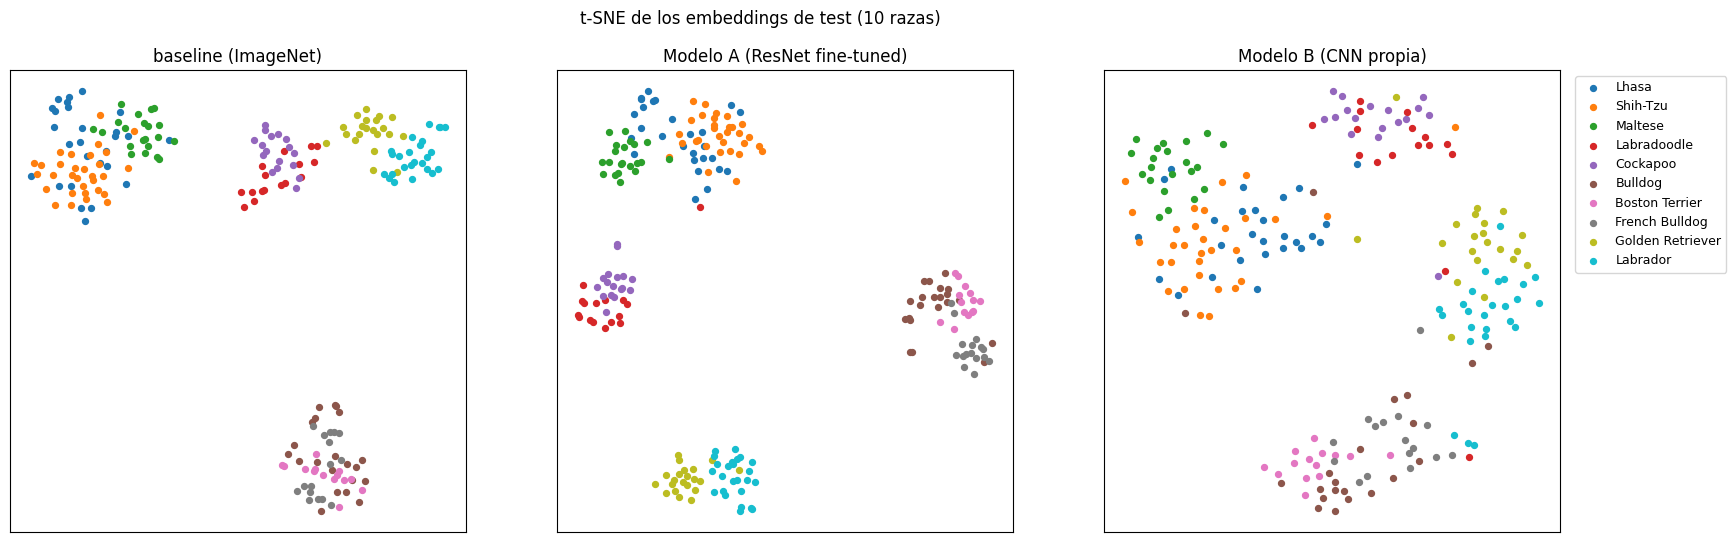

In [24]:
from torch.utils.data import DataLoader
from sklearn.manifold import TSNE
from lib.services.classifier_service import _ImagenesRaza

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"

def embeddings_modelo(ruta, rutas, batch_size=128):
    """Embeddings L2 de la capa previa al clasificador, en lote y en GPU."""
    red = torch.load(ruta, map_location="cpu", weights_only=False).to(dispositivo).eval()
    cargador = DataLoader(_ImagenesRaza(list(rutas), [0] * len(rutas), settings.image_size),
                          batch_size=batch_size, num_workers=2)
    salidas = []
    with torch.no_grad():
        for x, _ in cargador:
            salidas.append(torch.nn.functional.normalize(red.embedding(x.to(dispositivo)), dim=1).cpu())
    return torch.cat(salidas).numpy().astype(np.float32)

emb_baseline = emb  # embeddings de la sección 5 (ResNet18 de ImageNet)
emb_por_modelo = {"baseline (ImageNet)": emb_baseline}
for nombre, ruta in {"Modelo A (ResNet fine-tuned)": RUTA_A, "Modelo B (CNN propia)": RUTA_B}.items():
    emb_por_modelo[nombre] = {c: embeddings_modelo(ruta, conjuntos[c]["ruta"]) for c in ["train", "test", "independiente"]}

# Verificación: el cálculo en lote coincide con la función de la app
classifier.set_active_model("resnet18_finetuned"); classifier._loaded.pop("resnet18_finetuned", None)
uno = np.array(classifier.extract_custom_embedding(leer_imagen(conjuntos["test"].at[0, "ruta"])))
print("Diferencia máxima con extract_custom_embedding:",
      float(np.abs(uno - emb_por_modelo["Modelo A (ResNet fine-tuned)"]["test"][0]).max()))

# Misma evaluación de la Etapa 1 con cada tipo de embedding
filas = []
for nombre, emb in emb_por_modelo.items():  # `evaluar` (sección 5) usa la variable emb
    for consultas in ["test", "independiente"]:
        r = evaluar(consultas, k_voto=K_VOTO)
        filas.append({"embeddings": nombre, "consultas": consultas, "NDCG@10": r["ndcg@10"].mean(),
                      "precision@10": r["precision@10"].mean(), "accuracy": r["acierto"].mean()})
emb = emb_baseline  # se restaura
tabla_ndcg = pd.DataFrame(filas)
display(tabla_ndcg.pivot(index="embeddings", columns="consultas", values=["NDCG@10", "accuracy"]).round(3))

# t-SNE de test con 10 razas
RAZAS_TSNE = ["Lhasa", "Shih-Tzu", "Maltese", "Labradoodle", "Cockapoo", "Bulldog", "Boston Terrier",
              "French Bulldog", "Golden Retriever", "Labrador"]
mascara = conjuntos["test"]["raza"].isin(RAZAS_TSNE).to_numpy()
razas_sel = conjuntos["test"]["raza"].to_numpy()[mascara]
fig, ejes = plt.subplots(1, 3, figsize=(20, 6))
for eje, (nombre, e) in zip(ejes, emb_por_modelo.items()):
    puntos = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(e["test"][mascara])
    for raza in RAZAS_TSNE:
        sel = razas_sel == raza
        eje.scatter(puntos[sel, 0], puntos[sel, 1], s=18, label=raza)
    eje.set_title(nombre); eje.set_xticks([]); eje.set_yticks([])
ejes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.suptitle("t-SNE de los embeddings de test (10 razas)"); plt.show()

**Resultado.**
- **Verificación:** los embeddings calculados en lote coinciden con `extract_custom_embedding`
  (diferencia máxima ≈3·10⁻⁷, error de redondeo).

| Embeddings | NDCG@10 test | Accuracy test | NDCG@10 independiente | Accuracy independiente |
|---|---|---|---|---|
| Baseline (ImageNet) | 0,819 | 88,7% | **0,698** | **77,8%** |
| Modelo A (ResNet fine-tuned) | **0,880** | **90,8%** | 0,630 | 65,4% |
| Modelo B (CNN propia) | 0,560 | 63,8% | 0,161 | 21,0% |

- **En `test`, los embeddings del Modelo A son los mejores** (NDCG@10 0,880 frente a 0,819 del
  baseline): el fine-tuning reorganiza el espacio para separar razas.
- **En el conjunto independiente gana el baseline** (0,698 frente a 0,630): el ajuste al dataset
  mejora dentro del dominio pero pierde robustez fuera de él, igual que se observó con la
  clasificación (sección 8).
- Los embeddings del Modelo B quedan muy por debajo en ambos conjuntos.
- **t-SNE:** con el baseline, los grupos de razas parecidas aparecen mezclados (Lhasa, Shih-Tzu y
  Maltese en una sola nube; Labradoodle y Cockapoo juntos; Bulldog, Boston Terrier y French
  Bulldog superpuestos). Con el **Modelo A** los grupos son más compactos y se separan mejor:
  Golden y Labrador quedan en dos nubes distintas, French Bulldog se separa del resto y Maltese se
  distingue de Lhasa/Shih-Tzu; Bulldog y Boston Terrier siguen mezclados (ruido de etiquetas).
  Con el **Modelo B** las nubes son más dispersas y se mezclan más, coherente con su menor
  desempeño.

## 10. Análisis de errores

Errores del modelo elegido (Modelo A) ordenados por confianza: cada imagen mal clasificada es un
**falso negativo** de su raza real y un **falso positivo** de la raza predicha. Los errores con alta
confianza son los más informativos, porque el modelo "está seguro" y aun así se equivoca.

Modelo A: errores con mayor confianza en test: 131 errores de 1287 imágenes


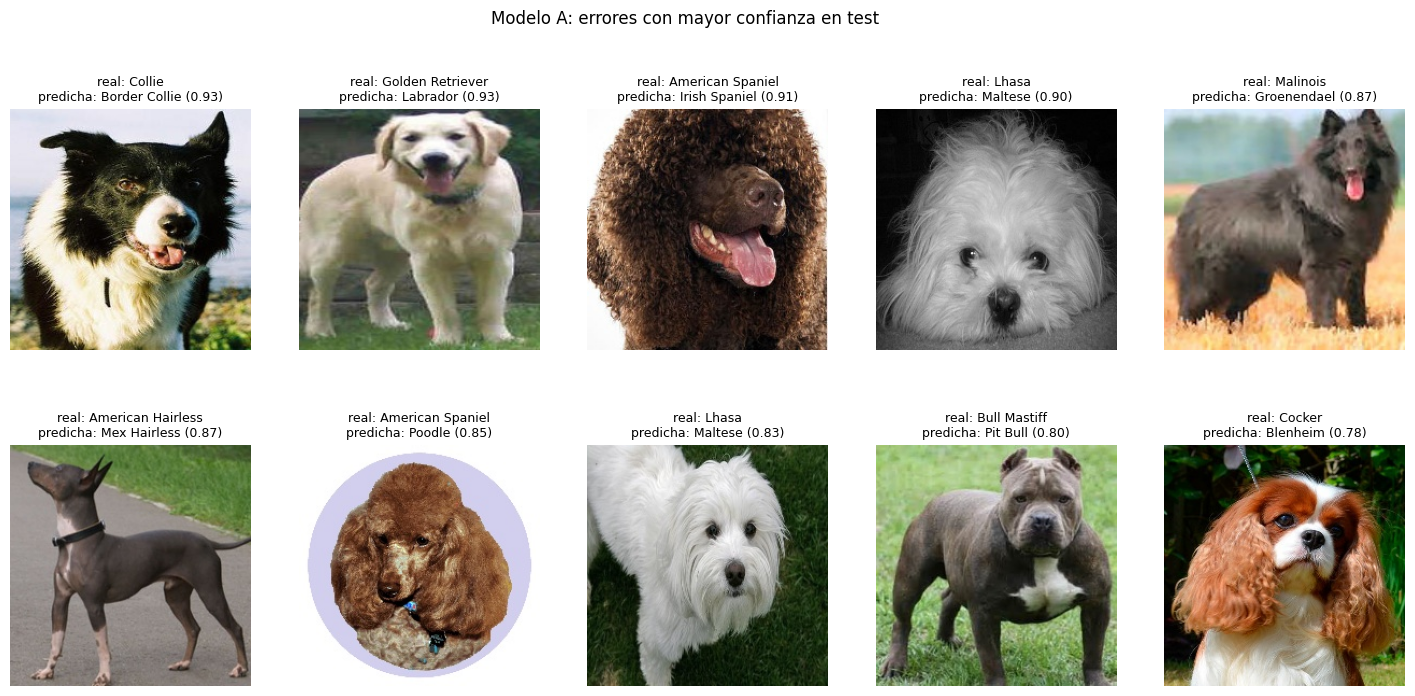

Modelo A: errores con mayor confianza en el conjunto independiente: 65 errores de 162 imágenes


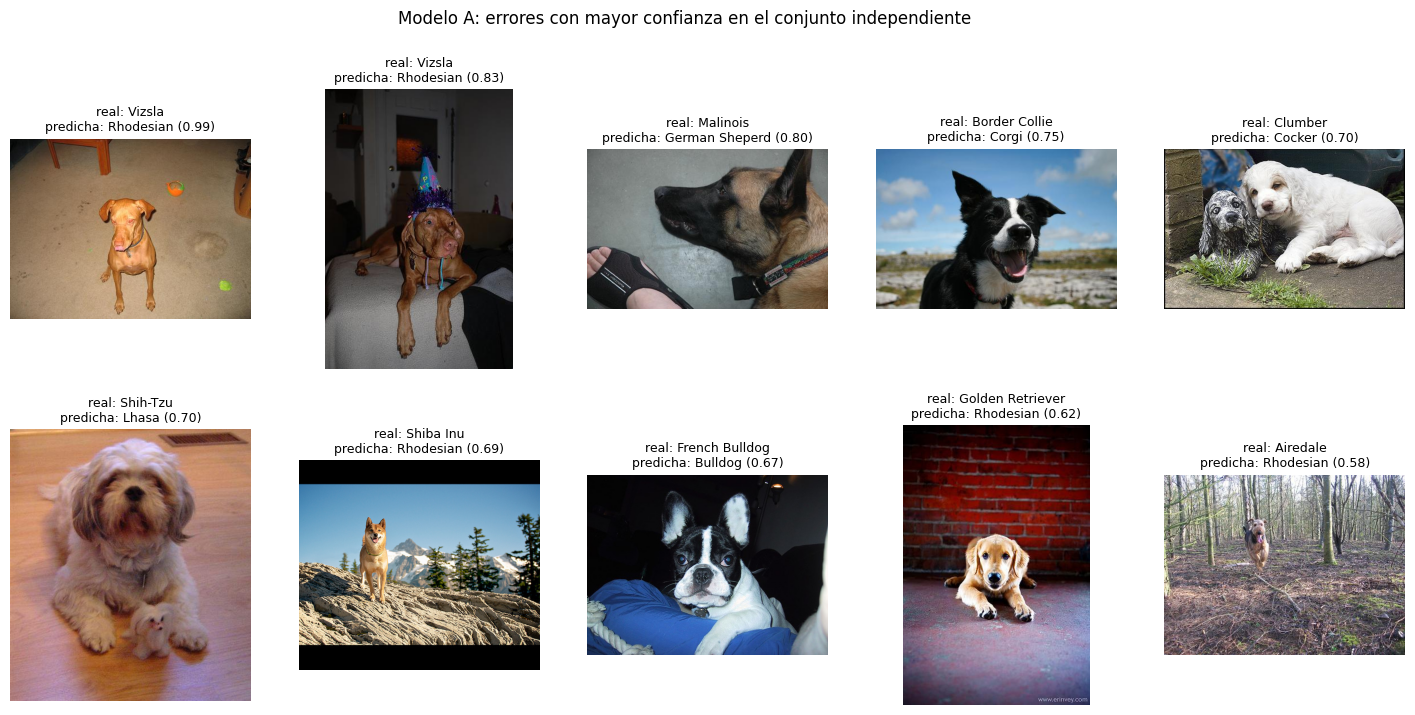

Confianza mediana — aciertos: 0.82 | errores: 0.42


In [22]:
from PIL import Image

def grilla_errores(ev, titulo, n=10):
    probas, razas = ev["probas"], np.array(ev["razas"])
    errores = np.where(ev["y_pred"] != ev["y_real"])[0]
    print(f"{titulo}: {len(errores)} errores de {len(ev['y_real'])} imágenes")
    errores = errores[np.argsort(-probas[errores, ev["y_pred"][errores]])][:n]
    fig, ejes = plt.subplots(2, 5, figsize=(18, 8))
    for eje, i in zip(ejes.ravel(), errores):
        eje.imshow(Image.open(ev["rutas"][i]).convert("RGB")); eje.axis("off")
        eje.set_title(f"real: {razas[ev['y_real'][i]]}\npredicha: {razas[ev['y_pred'][i]]} ({probas[i, ev['y_pred'][i]]:.2f})",
                      fontsize=9)
    plt.suptitle(titulo); plt.show()

grilla_errores(ev_a, "Modelo A: errores con mayor confianza en test")
grilla_errores(ev_ind_a, "Modelo A: errores con mayor confianza en el conjunto independiente")

# ¿La confianza (softmax) separa aciertos de errores?
confianza = ev_a["probas"].max(axis=1)
acierta = ev_a["y_pred"] == ev_a["y_real"]
print(f"Confianza mediana — aciertos: {np.median(confianza[acierta]):.2f} | errores: {np.median(confianza[~acierta]):.2f}")

**Resultado.**
- **Test:** 131 errores de 1.287 imágenes (10,2%). **Conjunto independiente:** 65 de 162 (40%).
- **Varios errores con alta confianza en `test` parecen errores de etiqueta del dataset:** la foto
  "Collie" es a la vista un Border Collie (0,93), la "Malinois" es negra de pelo largo como un
  Groenendael, la "Bull Mastiff" tiene aspecto de Pit Bull, la "Cocker" es un Cavalier
  (Blenheim) y la "American Spaniel" con marco circular es un caniche. En esos casos el modelo
  predice lo que se ve, y la etiqueta es la que está mal.
- **El resto son razas genuinamente parecidas:** Golden Retriever → Labrador (pelaje claro),
  Lhasa → Maltese (perros blancos de pelo largo; una de ellas es una foto en blanco y negro) y
  American Hairless → Mex Hairless.
- **En el conjunto independiente aparece un patrón distinto:** la raza **Rhodesian** funciona como
  "raza comodín" para perros chicos dentro de la foto, de pelaje marrón o dorado, en escenas con
  mucho fondo (Vizsla, Shiba Inu, Golden Retriever y Airedale predichos como Rhodesian). Son
  justamente los casos donde el perro ocupa poco espacio y el relleno agrega bandas grises
  (sección 8): el modelo, que aprendió con perros grandes y centrados, se apoya en el color
  general. También aparecen French Bulldog → Bulldog (ruido de etiquetas del dataset) y fotos
  con dos perros o con el perro recortado (Clumber, Malinois).
- **La confianza del softmax sí separa aciertos de errores:** mediana 0,82 en aciertos frente a
  0,42 en errores. A diferencia del score de similitud de la Etapa 1, la probabilidad del
  clasificador es una señal útil para responder `"unknown"` cuando el modelo duda.

## 11. Costo computacional

Para cada modelo: cantidad de parámetros, tamaño en memoria (parámetros × 4 bytes, float32),
tiempo de inferencia por imagen en CPU (promedio de 30 pasadas de una imagen, después de 5 de
calentamiento, como en la app) y dimensión del embedding.

In [25]:
import time
from lib.preprocesamiento import preprocesar

def costo(nombre, red, dim):
    red = red.eval().cpu()
    x = preprocesar(leer_imagen(conjuntos["test"].at[0, "ruta"]), settings.image_size).unsqueeze(0)
    with torch.no_grad():
        for _ in range(5): red(x)  # calentamiento
        inicio = time.perf_counter()
        for _ in range(30): red(x)
    params = sum(p.numel() for p in red.parameters())
    return {"modelo": nombre, "parámetros (M)": round(params / 1e6, 2), "tamaño (MB)": round(params * 4 / 2**20, 1),
            "latencia CPU (ms/imagen)": round((time.perf_counter() - inicio) / 30 * 1000, 1), "dim. embedding": dim}

tabla_costo = pd.DataFrame([
    costo("Baseline (ResNet18 ImageNet, solo embedding)", similarity._cargar_modelo(), 512),
    costo("Modelo A (ResNet18 fine-tuned)", torch.load(RUTA_A, map_location="cpu", weights_only=False), 512),
    costo("Modelo B (CNN propia)", torch.load(RUTA_B, map_location="cpu", weights_only=False), 512),
]).set_index("modelo")
display(tabla_costo)

,parámetros (M),tamaño (MB),latencia CPU (ms/imagen),dim. embedding
modelo,,,,
"Baseline (ResNet18 ImageNet, solo embedding)",11.18,42.6,30.6,512
Modelo A (ResNet18 fine-tuned),11.21,42.8,29.9,512
Modelo B (CNN propia),5.01,19.1,46.2,512


**Resultado.**

| Modelo | Parámetros | Tamaño | Latencia CPU | Dim. embedding |
|---|---|---|---|---|
| Baseline (ResNet18 ImageNet) | 11,18 M | 42,6 MB | 30,6 ms | 512 |
| Modelo A (ResNet18 fine-tuned) | 11,21 M | 42,8 MB | 29,9 ms | 512 |
| Modelo B (CNN propia) | 5,01 M | 19,1 MB | 46,2 ms | 512 |

- El Modelo A cuesta lo mismo que el baseline: es la misma red con una capa final de 70 salidas
  (+0,03 M de parámetros).
- **El Modelo B ocupa la mitad pero es ≈50% más lento.** La latencia no depende solo de la cantidad
  de parámetros, sino de cuántas operaciones se hacen: la ResNet18 reduce la imagen a 56×56 en sus
  primeras capas (convolución con stride 2 y max pooling), mientras que la CNN propia aplica dos
  convoluciones sobre la imagen completa de 224×224 en su primer bloque. Menos parámetros no
  implica menos cómputo.
- Los tres modelos responden en menos de 50 ms por imagen en CPU, aceptable para la app, y los
  tres usan embeddings de 512, compatibles con `EMBEDDING_DIM` sin reindexar con otra dimensión.

## 12. Comparación y elección final

Tabla con todas las métricas de la Etapa 1 (búsqueda por similitud) y la Etapa 2 (clasificación),
en `test` y en el conjunto independiente, junto con el costo de cada modelo.

In [28]:
nd = tabla_ndcg.set_index(["embeddings", "consultas"])
nombres = {"baseline (ImageNet)": "Baseline (ImageNet)", "Modelo A (ResNet fine-tuned)": "Modelo A (ResNet fine-tuned)",
           "Modelo B (CNN propia)": "Modelo B (CNN propia)"}
costos = tabla_costo.set_axis(list(nombres.values()))
clasif = {"Modelo A (ResNet fine-tuned)": ("Modelo A", metrics_a), "Modelo B (CNN propia)": ("Modelo B", metrics_b)}
filas = []
for clave, nombre in nombres.items():
    fila = {"modelo": nombre,
            "Etapa 1 · NDCG@10 test": nd.loc[(clave, "test"), "NDCG@10"],
            "Etapa 1 · NDCG@10 indep.": nd.loc[(clave, "independiente"), "NDCG@10"],
            "Etapa 1 · accuracy test": nd.loc[(clave, "test"), "accuracy"],
            "Etapa 1 · accuracy indep.": nd.loc[(clave, "independiente"), "accuracy"]}
    if nombre in clasif:
        etiqueta, met = clasif[nombre]
        fila.update({"Etapa 2 · accuracy test": met["accuracy"], "Etapa 2 · F1 test": met["f1"],
                     "Etapa 2 · accuracy indep.": tabla_indep.loc[etiqueta, "accuracy independiente"]})
    fila.update(costos.loc[nombre, ["parámetros (M)", "tamaño (MB)", "latencia CPU (ms/imagen)"]].to_dict())
    filas.append(fila)
comparacion_final = pd.DataFrame(filas).set_index("modelo").T
display(comparacion_final.round(3))

modelo,Baseline (ImageNet),Modelo A (ResNet fine-tuned),Modelo B (CNN propia)
Etapa 1 · NDCG@10 test,0.819,0.880,0.560
Etapa 1 · NDCG@10 indep.,0.698,0.630,0.161
Etapa 1 · accuracy test,0.887,0.908,0.638
Etapa 1 · accuracy indep.,0.778,0.654,0.210
parámetros (M),11.180,11.210,5.010
tamaño (MB),42.600,42.800,19.100
latencia CPU (ms/imagen),30.600,29.900,46.200
Etapa 2 · accuracy test,NaN,0.898,0.654
Etapa 2 · F1 test,NaN,0.898,0.653
Etapa 2 · accuracy indep.,NaN,0.599,0.173


**Resultado y elección final.**

**Clasificación (Etapas 2 y 3): Modelo A (ResNet18 fine-tuned).** Es claramente superior a la CNN
propia en `test` (accuracy 89,8% vs. 65,4%) y en el conjunto independiente (59,9% vs. 17,3%), con
una latencia similar o menor (≈30 ms vs. 46 ms por imagen en CPU). El Modelo B ocupa menos memoria
(19 MB vs. 43 MB), pero esa ventaja no compensa 24 puntos menos de accuracy.

**Búsqueda por similitud (`EMBEDDING_MODEL`): baseline (ResNet18 de ImageNet).** Los embeddings del
Modelo A son mejores en `test` (NDCG@10 0,880 vs. 0,819), pero el baseline es mejor con fotos
reales del conjunto independiente (0,698 vs. 0,630; accuracy 77,8% vs. 65,4%), que es lo que
recibirá la app. Además, el umbral `SIMILARITY_THRESHOLD = 0,78` se calibró con estos embeddings y
no requiere checkpoint entrenado. Configuración: `EMBEDDING_MODEL=baseline`, `EMBEDDING_DIM=512`,
`TOP_K=10`, `SIMILARITY_THRESHOLD=0.78`.

**Búsqueda por similitud vs. clasificación supervisada.**

| | Búsqueda por similitud | Clasificación supervisada |
|---|---|---|
| Entrenamiento | No requiere: basta con indexar la galería | Requiere entrenar con imágenes etiquetadas |
| Nuevas razas | Se agregan indexando sus fotos, sin reentrenar | Requieren reentrenar (la salida tiene 70 clases fijas) |
| Explicabilidad | Muestra las imágenes en las que se basa la decisión | Solo devuelve una probabilidad |
| Costo de inferencia | Embedding + búsqueda en la base (crece con la galería) | Una pasada de la red, sin base de datos |
| Robustez fuera del dataset | Mayor en este trabajo (77,8% en el independiente) | Menor (59,9%): se ajustó al estilo del dataset |
| Desempeño en el dominio | 88,7% en `test` (baseline) | 89,8% en `test` (Modelo A) |
| Rechazo de imágenes ajenas | Umbral de similitud (rechaza ≈90% de imágenes sin perro) | La probabilidad separa aciertos (mediana 0,82) de errores (0,42) |

**Cuándo conviene cada una:** la clasificación cuando las imágenes se parecen a las de
entrenamiento y se necesita una respuesta rápida, sin base de datos; la búsqueda cuando las
categorías cambian, cuando conviene mostrar ejemplos que justifiquen la respuesta o cuando las
imágenes vienen de fuentes variadas. Un dato interesante: usar los embeddings del Modelo A *dentro*
de la búsqueda (90,8% en `test`) supera levemente al propio clasificador (89,8%), porque el voto de
los 10 vecinos suaviza errores individuales.

**Trade-offs de precisión, velocidad y memoria:** el Modelo A ofrece la mejor precisión en el
dominio con el mismo costo que el baseline; la CNN propia reduce la memoria a menos de la mitad,
pero es más lenta y mucho menos precisa. La principal limitación detectada es la **robustez fuera
del dataset**: incorporar a la augmentation relleno y encuadres aleatorios (sección 8) es la mejora
prioritaria para un trabajo futuro.

## 13. Checkpoints
Los checkpoints elegidos se guardan como modelos completos (`torch.save(model)`), con la lista de
razas incluida, en `models/resnet18_finetuned.pth` y `models/cnn_custom.pth`. No se suben al
repositorio (`*.pth` está en `.gitignore`): se publican en Google Drive con link de solo lectura
(ver README y PR) y se colocan en `models/` para que la app los use.

In [29]:
# Checkpoints que usa la app (en Kaggle se descargan desde el panel Output: /kaggle/working/proyecto/models)
for nombre in [settings.resnet18_model_name, settings.cnn_custom_model_name]:
    ruta = settings.model_path / nombre
    red = torch.load(ruta, map_location="cpu", weights_only=False)
    print(f"{ruta}: {ruta.stat().st_size / 2**20:.1f} MB | {type(red).__name__} | {len(red.razas)} razas")

models/resnet18_finetuned.pth: 42.9 MB | ResNetRazas | 70 razas
models/cnn_custom.pth: 19.2 MB | CNNPropia | 70 razas
